# Real-space RG: blocks → superblocks → effective lattice

**One block = one triangle. One superblock = four neighboring triangles.**

## Direct route: omit the triangle approximation

**We can skip both triangle diagonalization and the cutoff $m$ entirely.** Group four physical triangles into a 12-spin superblock. Construct its full $2^{12}=4096$ dimensional Hamiltonian $H_S$, including every internal bond and field, and retain its lowest $\chi$ eigenstates directly. Bonds leaving the superblock enter when coupling the retained superblocks.

$$
\underbrace{\text{four physical triangles}}_{8^4=4096\text{ states}}
\xrightarrow{\text{diagonalize }H_S;\ \text{keep }\chi}
\underbrace{\text{one retained superblock}}_{\chi\text{ states}}
\xrightarrow{\text{glue all }N_{\mathrm{SB}}\text{ superblocks}}
\underbrace{\text{full effective theory}}_{\chi^{N_{\mathrm{SB}}}\text{ states}}.
$$

Let $D_S\in\mathbb C^{4096\times\chi}$ collect these eigenvectors in the physical-spin basis. With physical-spin operators $Z_i^{(S)}$ represented in the same superblock space,

$$
H_SD_S=D_S\operatorname{diag}(E_{S,1},\ldots,E_{S,\chi}),\qquad
h'_S=D_S^\dagger H_SD_S,\qquad
z_i'^{(S)}=D_S^\dagger Z_i^{(S)}D_S.
$$

Use these retained matrices in the full-lattice coupling of step 4 below. For $L=6$ and $\chi=8$, the whole-system dimension changes directly as

$$
\boxed{2^{108}=(2^{12})^9\ \longrightarrow\ 8^9=134{,}217{,}728.}
$$

**This removes one approximation.** It costs a larger local eigenproblem (4096 rather than 1296 dimensions for $m=6$); retaining only $\chi$ superblock states remains an approximation. The $m=8$ two-stage route is a change of coordinates for this same full-superblock problem, so the preliminary triangle rotation is unnecessary. Removing the triangle cutoff alone does not establish convergence of the final observables.

### Optional two-stage implementation

The diagram, dimension table, and steps 1–3 below describe the computational shortcut used by the current $m=6$ calculation:

$$
\underbrace{8\to m}_{\text{each triangle}}
\quad\longrightarrow\quad
\underbrace{m\times m\times m\times m=m^4}_{\text{glue four blocks}}
\quad\longrightarrow\quad
\underbrace{m^4\to\chi}_{\text{retain superblock states}}.
$$

**Notation throughout:** no hat = a matrix in its own block space; a hat = that matrix tensored with identities in a larger space. The label $[S]$ means the four-triangle superblock; $[\mathrm{eff}]$ means the full effective lattice. A prime means superblock retention, not embedding.

**Optional two-stage route: the direct route above skips the first rotation and retention.**

![Triangle: 8 states. Rotate and keep m eigenvectors. Glue four triangles with joining bonds: m^4 states. Rotate and keep chi eigenvectors. Glue all retained superblocks with crossing bonds to form the full effective theory with N_SB superblocks and chi^(N_SB) states.](attachment:full_rg_hierarchy.png)
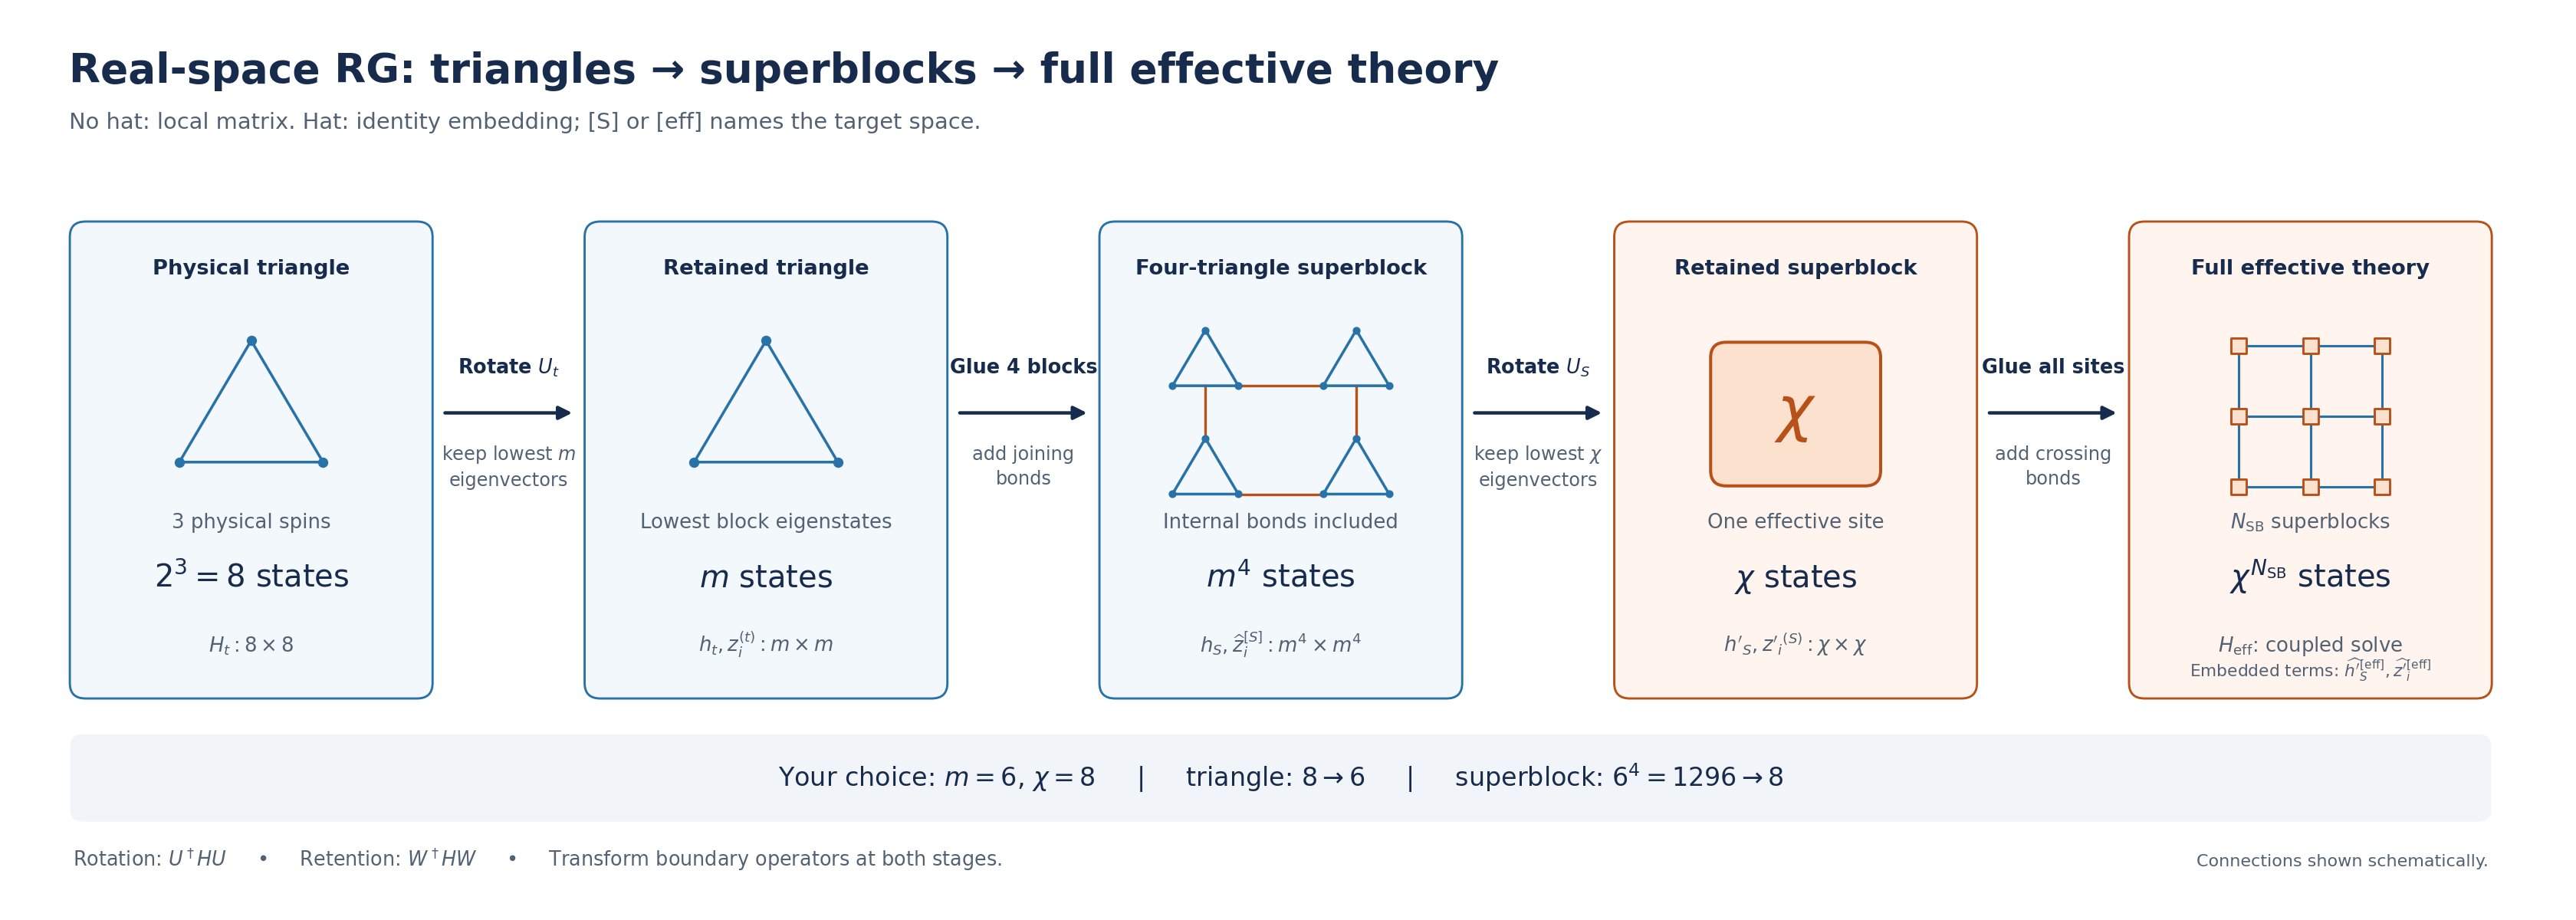

## Dimension summary: optional two-stage route

**Dimension means number of basis states; a Hamiltonian on $d$ states is a $d\times d$ matrix.** Rows 1–7 concern one triangle or one superblock; the last concerns the full lattice.

| Step | Region | State-space dimension $d$ | Hamiltonian matrix size | $L=6,\ m=6,\ \chi=8$: $d$ |
|:--|:--|:--|:--|--:|
| Physical spins | One triangle (3 spins) | $2^3=8$ | $H_t$: $8\times8$ | 8 |
| Rotate with $U_t$ | One triangle | $8$ | $U_t^\dagger H_tU_t$: $8\times8$ | 8 |
| Keep $m$ eigenvectors | One retained triangle | $m$ | $h_t$: $m\times m$ | 6 |
| Glue 4 triangles; add joining bonds | One superblock | $m^4$ | $h_S$: $m^4\times m^4$ | 1,296 |
| Rotate with $U_S$ | One superblock | $m^4$ | $U_S^\dagger h_SU_S$: $m^4\times m^4$ | 1,296 |
| Keep $\chi$ eigenvectors | One retained superblock | $\chi$ | $h'_S$: $\chi\times\chi$ | 8 |
| Identify as an effective site | One effective site | $\chi$ | $h'_S$: $\chi\times\chi$ | 8 |
| Glue $N_{\mathrm{SB}}$ superblocks; add crossing bonds | Full effective lattice | $\chi^{N_{\mathrm{SB}}}$ | $H_{\mathrm{eff}}$: $\chi^{N_{\mathrm{SB}}}\times\chi^{N_{\mathrm{SB}}}$ | 134,217,728 |

For the whole physical lattice, $N=3L^2$ spins give $N/3$ triangles and $N_{\mathrm{SB}}=N/12=L^2/4$ four-triangle superblocks:

$$
\underbrace{2^N}_{\text{physical lattice}}
\xrightarrow{\text{keep }m\text{ per triangle}}
\underbrace{m^{N/3}=(m^4)^{N_{\mathrm{SB}}}}_{\text{triangle-retained lattice}}
\xrightarrow{\text{keep }\chi\text{ per superblock}}
\underbrace{\chi^{N_{\mathrm{SB}}}}_{\text{final effective lattice}}.
$$

For $L=6$: $N=108$, 36 triangles, $N_{\mathrm{SB}}=9$, so

$$
\boxed{2^{108}\ \longrightarrow\ 6^{36}\ \longrightarrow\ 8^9=134{,}217{,}728.}
$$

Rotations and regrouping do not reduce the whole-lattice dimension; retaining eigenvectors does. Matrix sizes here are formal and do not imply dense storage. Hats remain reserved for identity-embedded terms, not the Hamiltonian in its own space.

## 1. Prepare each triangle block

For triangle $t$, $X_i^{(t)},Z_i^{(t)}$ are its $8\times8$ physical-spin matrices. Put its internal bonds and fields in

$$
H_t=\sum_{\langle ij\rangle\subset t}K_{ij}Z_i^{(t)}Z_j^{(t)}
-\Gamma\sum_{i\in t}X_i^{(t)}-h\sum_{i\in t}Z_i^{(t)}.
$$

**$m$ counts how many of the triangle's eight eigenstates we keep; $\chi$ counts how many eigenstates we keep for four coupled triangles.** These counts refer to different regions, so they need not match. Choosing $m=\chi=8$ is allowed.

| Triangle cutoff $m$ | Triangle eigenstates discarded | Four-triangle basis $m^4$ | Retained superblock states $\chi$ |
|--:|--:|--:|--:|
| 4 | 4 | 256 | 8 |
| 6 | 2 | 1,296 | 8 |
| 8 | 0 | 4,096 | 8 |

With $m=8$, the triangle step is only a basis change: nothing is discarded there. The superblock step still keeps only eight of its 4,096 eigenstates. Compared with $m=6$, the dense superblock matrix has about ten times as many entries, although the final effective dimension remains $8^{N_{\mathrm{SB}}}$. Thus $m<8$ is an optional computational shortcut, not a necessary part of blocking.

**What does smaller $m$ lose?** Even one superblock eigenstate can be a superposition of many triangle-product states. Joining bonds can mix higher-energy isolated-triangle states into low-energy superblock states. Discarding triangle eigenstates removes those components and their mixing effects from this projected model; keeping more superblock eigenstates later cannot restore them. The resulting energy and correlation errors must be checked, not inferred from how close $m$ is to $\chi$. This limitation of isolated-block energy truncation is discussed by S. R. White, *Physical Review B* **48**, 10345 (1993), Sections II–III.

Diagonalize its $8\times8$ matrix and retain the lowest $m$ eigenstates:

$$
U_t^\dagger H_tU_t=\operatorname{diag}(\epsilon_{t,1},\ldots,\epsilon_{t,8}),
\qquad V_t=(u_{t,1},\ldots,u_{t,m}),
$$
$$
h_t=V_t^\dagger H_tV_t,
\qquad z_i^{(t)}=V_t^\dagger Z_i^{(t)}V_t
\quad(i\in t).
$$

Carry forward $h_t$ and the boundary matrices $z_i^{(t)}$, each $m\times m$.

## 2. Glue four blocks into a superblock

Choose a connected group $S=(t_1,t_2,t_3,t_4)$. Its retained product basis is

$$
|\boldsymbol\alpha\rangle_S
=|u_{t_1,\alpha_1}\rangle\otimes\cdots\otimes|u_{t_4,\alpha_4}\rangle,
\qquad \alpha_p=1,\ldots,m;
\qquad \dim\mathcal H_S=m^4.
$$

Embed an operator on triangle $t_p$ by

$$
\widehat O_{t_p}^{[S]}=I_m^{\otimes(p-1)}\otimes O_{t_p}
\otimes I_m^{\otimes(4-p)}.
$$

The local operator is $m\times m$; its embedding acts on the entire superblock:

$$
O_{t_p}\in\mathbb C^{m\times m},
\qquad
\boxed{\widehat O_{t_p}^{[S]}\in\mathbb C^{m^4\times m^4}}.
$$

It applies $O_{t_p}$ to triangle $t_p$ and the identity to the other three triangles. For $m=6$:

$$
O_{t_p}:6\times6,
\qquad \widehat O_{t_p}^{[S]}:1296\times1296.
$$

For a spin $i$ in triangle $t_p$, write $\widehat z_i^{[S]}=I_m^{\otimes(p-1)}\otimes z_i^{(t_p)}\otimes I_m^{\otimes(4-p)}$. Thus $h_t,z_i^{(t)}$ are $m\times m$, while $\widehat h_t^{[S]},\widehat z_i^{[S]}$ are $m^4\times m^4$.

**Add the bonds joining different triangles inside this group:**

$$
\boxed{h_S=\sum_{p=1}^4\widehat h_{t_p}^{[S]}
+\sum_{(i,j)\in\mathcal E_{\rm join}(S)}
K_{ij}\widehat z_i^{[S]}\widehat z_j^{[S]}.}
$$

$\mathcal E_{\rm join}(S)$ counts each bond between distinct triangles in $S$ once. Triangle-internal bonds are already in $h_t$; bonds leaving $S$ wait until step 4.

This constructs the coupled $m^4\times m^4$ superblock Hamiltonian **before** its diagonalization. $h_S$ has no hat: it is the Hamiltonian in its own superblock space.

## 3. Rotate and truncate the superblock

$$
U_S^\dagger h_SU_S=\operatorname{diag}(E_{S,1},\ldots,E_{S,m^4}),
\qquad W_S=(u_{S,1},\ldots,u_{S,\chi})
\in\mathbb C^{m^4\times\chi}.
$$

Retain the lowest $\chi$ superblock eigenstates:

$$
|v_{S,a}\rangle=\sum_{\boldsymbol\alpha}(W_S)_{\boldsymbol\alpha a}
|\boldsymbol\alpha\rangle_S,
\qquad a=1,\ldots,\chi,
$$
$$
h'_S=W_S^\dagger h_SW_S,
\qquad z_i'^{(S)}=W_S^\dagger\widehat z_i^{[S]}W_S.
$$

The retained matrices $h'_S,z_i'^{(S)}$ are $\chi\times\chi$ and have no hats.

Square unitary $U_S$: exact similarity transformation. Rectangular $W_S$: truncation. Each retained state can mix all four triangles.

## 4. Glue all retained superblocks

The same identity-embedding rule now targets the full effective lattice. Order its $N_{\mathrm{SB}}$ superblocks by $S=1,\ldots,N_{\mathrm{SB}}$. For $O'_S\in\mathbb C^{\chi\times\chi}$,

$$
\widehat{O'}_S^{[\mathrm{eff}]}=I_\chi^{\otimes(S-1)}\otimes O'_S\otimes I_\chi^{\otimes(N_{\mathrm{SB}}-S)}
\in\mathbb C^{\chi^{N_{\mathrm{SB}}}\times\chi^{N_{\mathrm{SB}}}}.
$$

Use this embedding for $h'_S$ and each $z_i'^{(S)}$:

$$
\boxed{H_{\rm eff}=\sum_S\widehat{h'}_S^{[\mathrm{eff}]}
+\sum_{(i,j)\in\mathcal E_{\rm cross}}
K_{ij}\widehat{z'}_i^{[\mathrm{eff}]}\widehat{z'}_j^{[\mathrm{eff}]}.}
$$

Each $z_i'^{(S)}$ is embedded at the superblock containing $i$; $\mathcal E_{\rm cross}$ counts each bond between different superblocks once. Solve this coupled model jointly. $H_{\rm eff}$ has no hat: it already acts on its own full effective space.

For the optional two-stage route, the decoder combines both retention steps. For the direct route, $D_S$ is simply the matrix of retained physical-superblock eigenvectors:

$$
D_S=\left(\bigotimes_{t\in S}V_t\right)W_S
\in\mathbb C^{4096\times\chi},
\qquad \mathcal D=\bigotimes_SD_S,
$$
$$
H_{\rm eff}=\mathcal D^\dagger H_{\rm phys}\mathcal D,
\qquad |\Psi_{\rm phys}\rangle\approx\mathcal D|\psi_{\rm eff}\rangle.
$$

For another RG level, use retained superblocks as the new blocks and repeat steps 2–3.

## 5. Map back to physical spins and compute $P(q)$

**Procedure:** solve the coupled effective model → decode and sample physical spins → draw independent replica pairs → histogram their overlap.

### 1. Solve the coupled effective model

For a fixed field and disorder realization, obtain the joint state of all retained superblocks:

$$
H_{\mathrm{eff}}|\psi_{\mathrm{eff}}\rangle=E_0|\psi_{\mathrm{eff}}\rangle.
$$

The numerical solver approximates this ground state. Its joint amplitudes contain correlations between superblocks; the separate local eigenvectors alone are not the full-system state.

### 2. Map the state back to physical spins

**Keep the eigenvectors, not just their energies.** For each superblock, $D_S$ has 4096 rows (physical 12-spin configurations $\sigma_S$) and $\chi$ columns (retained eigenstates). Its entry $(D_S)_{\sigma_S a}$ is the amplitude of configuration $\sigma_S$ in retained state $a$. In the direct route these columns come from $H_S$; with triangle pretruncation use the composed decoder above.

Since $D_S^\dagger D_S=I_\chi$, the map lifts the normalized effective state into the original spin Hilbert space:

$$
|\Psi_{\mathrm{RG}}\rangle=\mathcal D|\psi_{\mathrm{eff}}\rangle,
\qquad \mathcal D=\bigotimes_{S=1}^{N_{\mathrm{SB}}}D_S.
$$

Writing $C_{a_1\ldots a_{N_{\mathrm{SB}}}}$ for the amplitudes of the solved, coupled effective state gives

$$
\boxed{\Psi_{\mathrm{RG}}(\sigma)=
\sum_{a_1,\ldots,a_{N_{\mathrm{SB}}}=1}^{\chi}
C_{a_1\ldots a_{N_{\mathrm{SB}}}}
\prod_{S=1}^{N_{\mathrm{SB}}}(D_S)_{\sigma_S a_S}.}
$$

### 3. Sample physical configurations conditionally

**Equivalent calculation entirely in the effective space.** Solve the coupled $H_{\mathrm{eff}}$ for $|\psi_{\mathrm{eff}}\rangle$. For each possible physical configuration of a superblock, define a $\chi\times\chi$ measurement matrix

$$
E_S(\sigma_S)=D_S^\dagger|\sigma_S\rangle\langle\sigma_S|D_S,
\qquad \sum_{\sigma_S}E_S(\sigma_S)=I_\chi.
$$

The physical configuration probability is then

$$
p_{\mathrm{RG}}(\sigma)=
\langle\psi_{\mathrm{eff}}|\bigotimes_SE_S(\sigma_S)|\psi_{\mathrm{eff}}\rangle.
$$

This is a measurement of the effective state with physical-spin outcomes, not an overlap of the retained eigenstate labels $a_S$.

**No full $2^{108}$ wavefunction array is needed.** The existing `joint_samples` routine contracts the retained state with decoder rows and samples physical block configurations conditionally, updating the remaining state after each outcome. A binary-prefix sampler chooses the 12 spins inside each block. It preserves interblock correlations and interference: sampling retained labels first and then decoding them as independent classical choices generally gives the wrong distribution. For the general tensor-network sampling methodology, see Ferris and Vidal, *Physical Review B* **85**, 165146 (2012).

Repeat this sampling process from the original effective state to obtain each independent full-spin configuration.

### 4. Pair replicas and histogram their overlaps

**Compute physical overlaps.** For a fixed disorder realization, draw two independent full-spin configurations $\sigma,\tau$ from $p_{\mathrm{RG}}(\sigma)=|\Psi_{\mathrm{RG}}(\sigma)|^2$, with $\sigma_i,\tau_i\in\{-1,+1\}$. Then

$$
q(\sigma,\tau)=\frac1N\sum_{i=1}^N\sigma_i\tau_i,
\qquad
P_{\mathrm{RG}}(q)=\sum_{\sigma,\tau}p_{\mathrm{RG}}(\sigma)p_{\mathrm{RG}}(\tau)
\delta_{q,q(\sigma,\tau)}.
$$

For $n_{\mathrm{pairs}}$ independent pairs $(\sigma^{(r)},\tau^{(r)})$, estimate the discrete probability mass by

$$
\boxed{P_{\mathrm{RG}}^{\mathrm{est}}(q)=
\frac{1}{n_{\mathrm{pairs}}}
\sum_{r=1}^{n_{\mathrm{pairs}}}
\mathbf 1\!\left[q=q(\sigma^{(r)},\tau^{(r)})\right],
\qquad \sum_qP_{\mathrm{RG}}^{\mathrm{est}}(q)=1.}
$$

This is a normalized histogram on $q=-1,-1+2/N,\ldots,1$, not a continuous probability density. For $L=6$, decode nine superblocks into 108 spins and compute the overlap on all 108 spins. Average the resulting distributions over disorder realizations afterward when a disorder-averaged $P(q)$ is wanted.

The lifting and conditional sampling are exact for the supplied retained-space state, up to numerical errors; the state itself approximates the original ground state, and finite-sample histograms have sampling error. Discarded states are not reconstructed.

**Implementation:** `triangle_effective_rg.py::joint_samples` performs physical sampling; `triangle_effective_l6_adaptive.py::run_case` forms replica-pair histograms. The active L6 D64 correlation scan instead measures physical overlap moments directly via `triangle_effective_mps.py::physical_moments` and `triangle_correlation_observables.py::overlap_observables`; these moments alone are not a full $P(q)$ histogram. For independent replicas,

$$
\langle q\rangle=\frac1N\sum_i\langle Z_i\rangle_{\mathrm{RG}}^2,
\qquad
\langle q^2\rangle=\frac1{N^2}\sum_{i,j}\langle Z_iZ_j\rangle_{\mathrm{RG}}^2.
$$